# Clustering

Anggota Kelompok:
1. yetri
2. Rusdianto

## Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Import Datasets

In [ ]:
wholesale = pd.read_csv("/content/Mall_Customers.csv")
wholesale.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [ ]:
wholesale.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## K-Means Clustering

In [ ]:
wholesale.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
# check missing values
wholesale.isna().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [ ]:
# check duplicates
wholesale.duplicated().sum()

np.int64(0)

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Mengambil kolom numerik saja untuk di-scaling (Age, Annual Income, Spending Score)
numeric_cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
scaler = MinMaxScaler()
wholesale_scaled = scaler.fit_transform(wholesale[numeric_cols])

pd.DataFrame(wholesale_scaled, columns=numeric_cols).describe()

,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,0.400962,0.373443,0.502041
std,0.268635,0.215285,0.263505
min,0.000000,0.000000,0.000000
25%,0.206731,0.217213,0.344388
50%,0.346154,0.381148,0.500000
75%,0.596154,0.516393,0.734694
max,1.000000,1.000000,1.000000


In [ ]:
# elbow method from k=1 to k=10
from sklearn.cluster import KMeans

# track sum of squared error
sse = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(wholesale_scaled)
    sse.append(kmeans.inertia_)

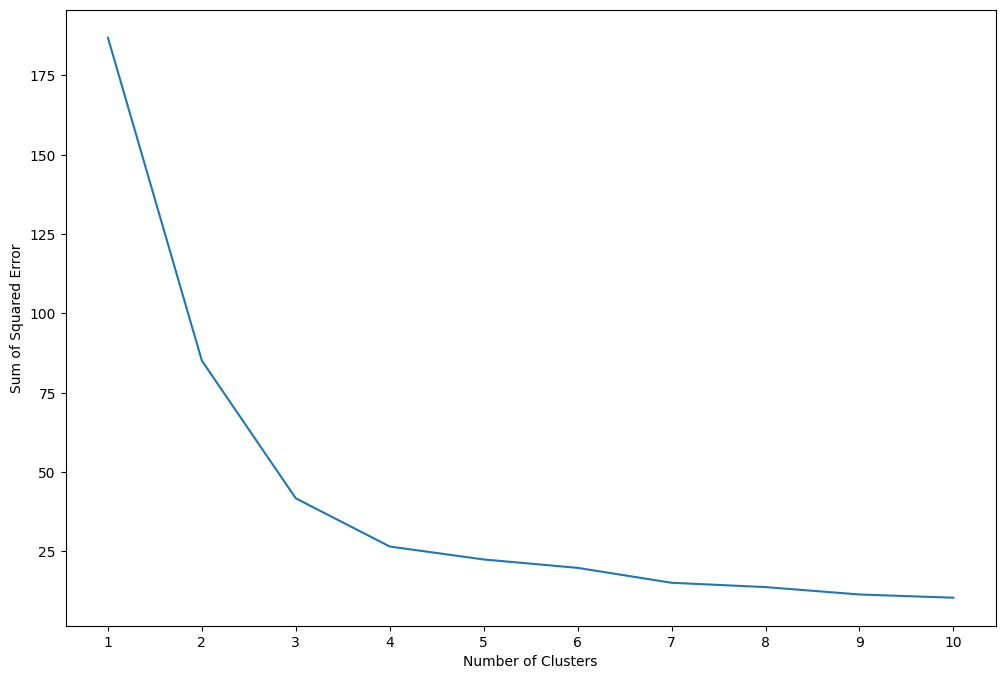

In [ ]:
# draw the SSE decline progression
import matplotlib.pyplot as plt
plt.figure(figsize = (12,8))
plt.plot(range(1,11), sse)
plt.xticks(range(1,11))
plt.xlabel("Number of Clusters")
plt.ylabel("Sum of Squared Error")
plt.show()

optimal k = 3

In [ ]:
# Melatih kembali k-means dengan data baru yang sudah di-scaling
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(wholesale_scaled)

# Menambahkan label ke dataframe
wholesale["label"] = kmeans.labels_
wholesale.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),label
0,1,Male,19,15,39,1
1,2,Male,21,15,81,1
2,3,Female,20,16,6,2
3,4,Female,23,16,77,1
4,5,Female,31,17,40,2


In [ ]:
# Menghitung rata-rata dari setiap kolom numerik berdasarkan label klaster baru
wholesale.groupby("label")[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].mean()

,Age,Annual Income (k$),Spending Score (1-100)
label,,,
0,55.983607,51.754098,40.688525
1,28.415730,61.168539,72.078652
2,36.520000,70.220000,22.860000


### Interpretasi Cluster Pelanggan (Mall Customers)

Berdasarkan nilai rata-rata (*mean*) dari fitur umur (*Age*), pendapatan tahunan (*Annual Income*), dan skor pengeluaran (*Spending Score*) pada masing-masing cluster di atas, kita dapat mengidentifikasi profil pelanggan sebagai berikut:

1. **Cluster 0: Pelanggan Senior Berpendapatan Menengah dengan Pengeluaran Sedang**
   * **Profil Umur:** Rata-rata **55.9 tahun** (Kelompok usia paling tua/senior).
   * **Pendapatan:** Rata-rata **$51.75k** per tahun (Menengah).
   * **Gaya Belanja:** Rata-rata skor pengeluaran **40.68** (Cenderung hemat dan berbelanja seperlunya).
   * **Target Strategi:** Kelompok ini adalah pelanggan loyal yang mengutamakan nilai produk. Promosi yang cocok adalah program loyalitas atau diskon khusus keluarga/lansia.

2. **Cluster 1: Pelanggan Muda Aktif & Impulsif (Konsumen Utama)**
   * **Profil Umur:** Rata-rata **28.4 tahun** (Sangat muda/Gen Z & Millennial).
   * **Pendapatan:** Rata-rata **$61.16k** per tahun (Menengah ke atas).
   * **Gaya Belanja:** Rata-rata skor pengeluaran sangat tinggi yaitu **72.07** (Sangat konsumtif dan suka berbelanja).
   * **Target Strategi:** Kelompok ini adalah penggerak penjualan utama. Strategi pemasaran terbaik adalah menawarkan produk tren terbaru, *flash sale*, serta kampanye digital yang menarik perhatian anak muda.

3. **Cluster 2: Pelanggan Produktif Hemat / Berhati-hati**
   * **Profil Umur:** Rata-rata **36.5 tahun** (Usia matang/produktif).
   * **Pendapatan:** Rata-rata paling tinggi yaitu **$70.22k** per tahun (Ekonomi kuat).
   * **Gaya Belanja:** Rata-rata skor pengeluaran paling rendah yaitu **22.86** (Sangat berhati-hati dalam membelanjakan uangnya).
   * **Target Strategi:** Kelompok ini memiliki daya beli tinggi namun sulit dirayu. Strategi terbaik adalah menawarkan produk premium, eksklusif, serta memberikan edukasi fungsionalitas dan kualitas produk yang rasional.

### Visualisasi Hasil Clustering menggunakan PCA (2D)

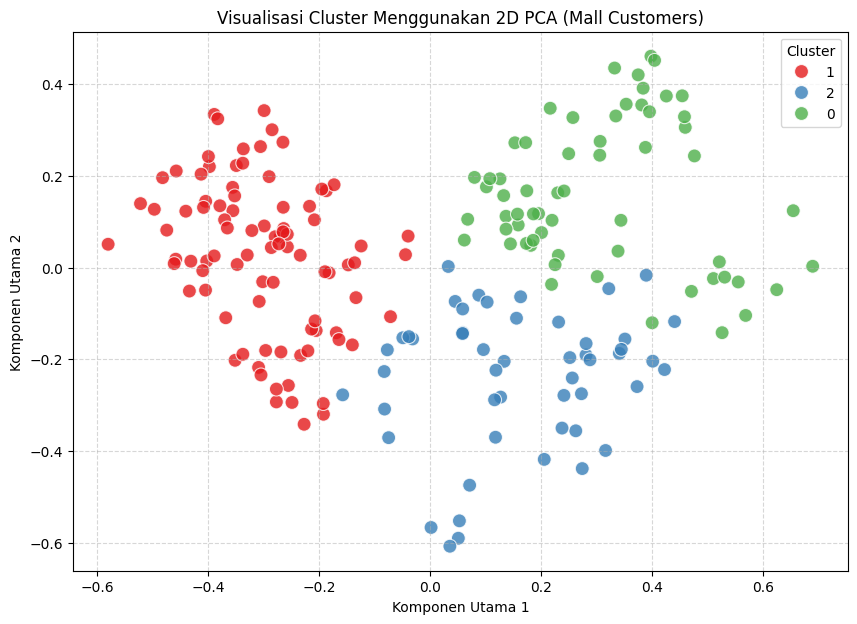

In [ ]:
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

# Reduksi dimensi menjadi 2 komponen utama dari data yang sudah di-scale (200 baris)
pca = PCA(n_components=2, random_state=42)
wholesale_pca = pca.fit_transform(wholesale_scaled)

# Membuat DataFrame baru untuk visualisasi
pca_df = pd.DataFrame(data=wholesale_pca, columns=['PCA1', 'PCA2'])
pca_df['Cluster'] = wholesale['label'].astype(str)

# Plot hasil clustering
plt.figure(figsize=(10, 7))
sns.scatterplot(x='PCA1', y='PCA2', hue='Cluster', data=pca_df, palette='Set1', s=100, alpha=0.8)
plt.title('Visualisasi Cluster Menggunakan 2D PCA (Mall Customers)')
plt.xlabel('Komponen Utama 1')
plt.ylabel('Komponen Utama 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Evaluasi Clustering dengan Davies-Bouldin Index

Davies-Bouldin Index (DBI) digunakan untuk mengevaluasi model clustering. Nilai DBI yang lebih rendah menunjukkan pemisahan cluster yang lebih baik dan konsistensi internal cluster yang lebih tinggi.

In [ ]:
# Davies-Bouldin Index (DBI)
from sklearn.metrics import davies_bouldin_score

db_index = davies_bouldin_score(
    wholesale_scaled,
    kmeans.labels_
)

print("=== DAVIES-BOULDIN INDEX ===")
print("Nilai DB Index:", db_index)

=== DAVIES-BOULDIN INDEX ===
Nilai DB Index: 1.190555932644573


### Analisis Evaluasi Davies-Bouldin Index (DBI)

* **Nilai DB Index:** **1.1906**
* **Interpretasi Nilai:**
  Nilai Davies-Bouldin Index sebesar **1.1906** menunjukkan bahwa model clustering $k=3$ memiliki tingkat pemisahan antar klaster yang cukup baik (karena nilainya mendekati angka 1).
  
  Secara teori, semakin kecil nilai DBI (semakin mendekati 0), maka pembagian kelompok tersebut semakin optimal (jarak di dalam klaster kecil/padat, dan jarak antar klaster besar/terpisah jauh). Dengan nilai 1.19, segmentasi ini sudah sangat layak dan relevan untuk digunakan sebagai landasan pengambilan keputusan bisnis.

Cluster interpretation?

# Selesai